
# Ejercicio 5: Descenso del gradiente con momento

**Materia:** Matemáticas para Inteligencia Artificial

## Función del problema

$$
f(x_1,x_2)=(1-x_1)^2+100(x_2-x_1^2)^2
$$

## Objetivo

Encontrar el mínimo de la función utilizando descenso del gradiente con momento.

Se realizarán las siguientes actividades:

1. Implementar la función, su gradiente y el descenso con momento.
2. Probar diferentes valores de tasa de aprendizaje, momento y punto inicial.
3. Continuar hasta alcanzar una norma del gradiente menor que $10^{-6}$ o justificar el límite de iteraciones.
4. Reportar el mínimo, el valor de la función, el gradiente final y el número de iteraciones.
5. Graficar el valor de la función contra las iteraciones.
6. Comparar con el método sin momento utilizando la misma tasa de aprendizaje y el mismo punto inicial.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:

# Función matemática del ejercicio 5
def f(x):
    x1, x2 = x

    return (1 - x1)**2 + 100*(x2 - x1**2)**2

# Punto inicial provisional
x0 = np.array([0.0, 0.0])

# Evaluar la función
print("Punto inicial:", x0)
print("Valor inicial:", f(x0))


Punto inicial: [0. 0.]
Valor inicial: 1.0


In [3]:

# Gradiente de la función
def gradiente(x):
    x1, x2 = x

    df_dx1 = 2*(x1 - 1) - 400*x1*(x2 - x1**2)
    df_dx2 = 200*(x2 - x1**2)

    return np.array([df_dx1, df_dx2])

# Evaluar el gradiente
print("Gradiente inicial:", gradiente(x0))
print("Norma inicial:", np.linalg.norm(gradiente(x0)))


Gradiente inicial: [-2.  0.]
Norma inicial: 2.0



## Implementación del descenso del gradiente con momento

Se aplica la fórmula:

$$
x_{i+1}=x_i-\gamma\nabla f(x_i)+\alpha\Delta x_i
$$

Donde:

$$
\Delta x_i=x_i-x_{i-1}
$$

Para la primera iteración, el desplazamiento inicial es cero.

El algoritmo continuará hasta alcanzar:

$$
\|\nabla f(x_i)\|<10^{-6}
$$

Se establece un máximo de iteraciones para evitar ejecuciones indefinidas.


In [4]:

def descenso_con_momento(x_inicial, gamma, alpha,
                         tolerancia=1e-6,
                         max_iteraciones=100000):

    x = np.array(x_inicial, dtype=float)
    delta_x = np.zeros_like(x)

    historial = [f(x)]
    trayectoria = [x.copy()]

    for i in range(max_iteraciones):

        g = gradiente(x)

        # Comprobar convergencia
        if np.linalg.norm(g) < tolerancia:
            return x, historial, trayectoria, i, "Convergió"

        # Actualizar utilizando momento
        nuevo_x = x - gamma*g + alpha*delta_x

        # Comprobar divergencia
        if (not np.all(np.isfinite(nuevo_x))
                or np.linalg.norm(nuevo_x) > 1e6):
            return x, historial, trayectoria, i, "Divergió"

        # Calcular desplazamiento
        delta_x = nuevo_x - x

        # Actualizar punto
        x = nuevo_x

        # Guardar resultados
        historial.append(f(x))
        trayectoria.append(x.copy())

    return x, historial, trayectoria, max_iteraciones, "Límite alcanzado"


In [5]:

# Parámetros de prueba
gamma = 0.001
alpha = 0.5
x0 = np.array([0.0, 0.0])

# Ejecutar descenso con momento
minimo, historial, trayectoria, iteraciones, estado = (
    descenso_con_momento(x0, gamma, alpha)
)

# Mostrar resultados
print("Estado:", estado)
print("Punto encontrado:", minimo)
print("Valor de la función:", f(minimo))
print("Gradiente final:", gradiente(minimo))
print("Norma del gradiente:", np.linalg.norm(gradiente(minimo)))
print("Número de iteraciones:", iteraciones)


Estado: Convergió
Punto encontrado: [0.99999888 0.99999776]
Valor de la función: 1.2501317386257276e-12
Gradiente final: [-4.46166097e-07 -8.94116736e-07]
Norma del gradiente: 9.992541838324467e-07
Número de iteraciones: 15636



## Pruebas de parámetros

Se prueban diferentes tasas de aprendizaje, coeficientes de momento y puntos iniciales.

El objetivo es identificar una combinación que permita alcanzar el mínimo con un número razonable de iteraciones.

Se utiliza el criterio de convergencia:

$$
\|\nabla f(x_i)\|<10^{-6}
$$


In [7]:

# Valores de prueba
tasas = [0.0001, 0.0005, 0.001]

momentos = [0.0, 0.5, 0.8]

puntos = [
    np.array([0.0, 0.0]),
    np.array([-1.0, 1.0]),
    np.array([0.5, 0.5])
]

resultados_pruebas = []

for punto in puntos:
    for tasa in tasas:
        for momento in momentos:

            minimo, historial, trayectoria, n_iter, estado = (
                descenso_con_momento(punto, tasa, momento)
            )

            resultados_pruebas.append({
                "Punto inicial": str(punto),
                "Gamma": tasa,
                "Alpha": momento,
                "Estado": estado,
                "Iteraciones": n_iter,
                "f(x) final": f(minimo),
                "Norma gradiente": np.linalg.norm(gradiente(minimo))
            })

tabla_pruebas = pd.DataFrame(resultados_pruebas)

display(tabla_pruebas)


,Punto inicial,Gamma,Alpha,Estado,Iteraciones,f(x) final,Norma gradiente
0,[0. 0.],0.0001,0.0,Límite alcanzado,100000,3.146800e-05,5.035941e-03
1,[0. 0.],0.0001,0.5,Límite alcanzado,100000,1.048510e-08,9.152075e-05
2,[0. 0.],0.0001,0.8,Convergió,62563,1.251528e-12,9.998119e-07
3,[0. 0.],0.0005,0.0,Convergió,62617,1.251549e-12,9.998203e-07
4,[0. 0.],0.0005,0.5,Convergió,31291,1.251918e-12,9.999678e-07
5,[0. 0.],0.0005,0.8,Convergió,12464,1.249709e-12,9.990852e-07
6,[0. 0.],0.0010,0.0,Convergió,31305,1.251425e-12,9.997708e-07
7,[0. 0.],0.0010,0.5,Convergió,15636,1.250132e-12,9.992542e-07
8,[0. 0.],0.0010,0.8,Convergió,6201,1.248871e-12,9.987503e-07
9,[-1. 1.],0.0001,0.0,Límite alcanzado,100000,5.673002e-05,6.772074e-03



## Comparación del descenso con momento y sin momento

Se comparan los dos métodos utilizando los mismos parámetros:

- Tasa de aprendizaje: $\gamma=0.001$
- Punto inicial: $x_0=(0,0)$
- Momento: $\alpha=0.8$
- Sin momento: $\alpha=0$

Se analizarán el número de iteraciones, el valor mínimo encontrado, el gradiente final y las trayectorias de ambos métodos.

El objetivo es determinar cuánto influye el momento en la convergencia.


In [8]:

# Parámetros seleccionados
gamma = 0.001
x0 = np.array([0.0, 0.0])

# Descenso CON momento
min_con, hist_con, tray_con, iter_con, estado_con = (
    descenso_con_momento(x0, gamma, 0.8)
)

# Descenso SIN momento
min_sin, hist_sin, tray_sin, iter_sin, estado_sin = (
    descenso_con_momento(x0, gamma, 0.0)
)

# Tabla comparativa
comparacion = pd.DataFrame({
    "Método": ["Con momento", "Sin momento"],
    "Alpha": [0.8, 0.0],
    "Estado": [estado_con, estado_sin],
    "Iteraciones": [iter_con, iter_sin],
    "f(x*)": [f(min_con), f(min_sin)],
    "Norma gradiente": [
        np.linalg.norm(gradiente(min_con)),
        np.linalg.norm(gradiente(min_sin))
    ]
})

display(comparacion)

# Porcentaje de reducción de iteraciones
if estado_con == "Convergió" and estado_sin == "Convergió":
    reduccion = (iter_sin - iter_con) / iter_sin * 100
    print(f"Reducción de iteraciones: {reduccion:.2f}%")

print("Mínimo con momento:", min_con)
print("Mínimo sin momento:", min_sin)
print("Gradiente final con momento:", gradiente(min_con))
print("Gradiente final sin momento:", gradiente(min_sin))


,Método,Alpha,Estado,Iteraciones,f(x*),Norma gradiente
0,Con momento,0.8,Convergió,6201,1.248871e-12,9.987503e-07
1,Sin momento,0.0,Convergió,31305,1.251425e-12,9.997708e-07


Reducción de iteraciones: 80.19%
Mínimo con momento: [0.99999888 0.99999776]
Mínimo sin momento: [0.99999888 0.99999776]
Gradiente final con momento: [-4.45941181e-07 -8.93665852e-07]
Gradiente final sin momento: [-4.46396847e-07 -8.94578944e-07]


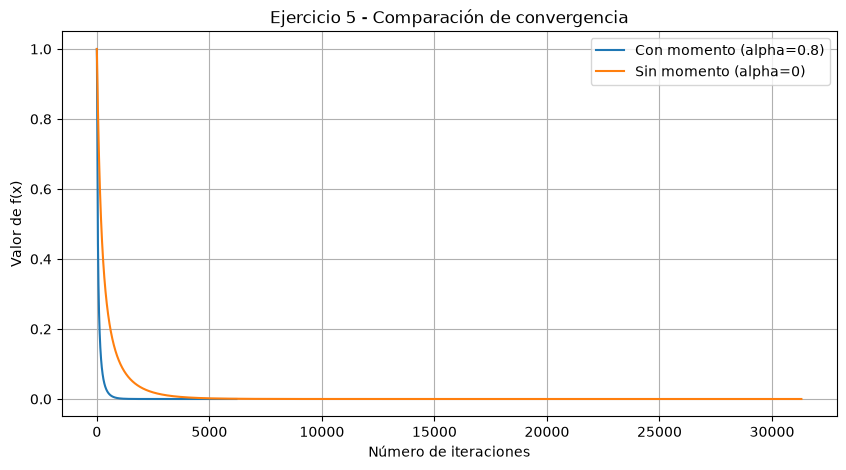

In [9]:

# Gráfica de convergencia
plt.figure(figsize=(10, 5))

plt.plot(hist_con, label="Con momento (alpha=0.8)")
plt.plot(hist_sin, label="Sin momento (alpha=0)")

plt.xlabel("Número de iteraciones")
plt.ylabel("Valor de f(x)")
plt.title("Ejercicio 5 - Comparación de convergencia")

plt.legend()
plt.grid(True)
plt.show()


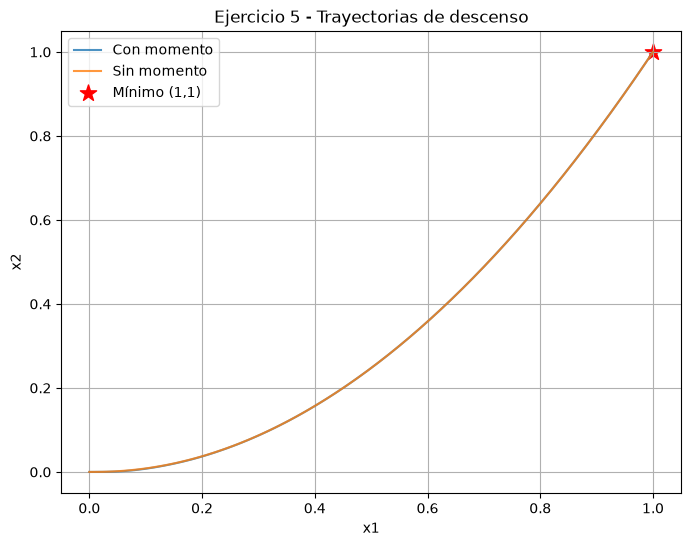

In [10]:

# Convertir trayectorias a arreglos
tray_con = np.array(tray_con)
tray_sin = np.array(tray_sin)

# Gráfica de trayectorias
plt.figure(figsize=(8, 6))

plt.plot(tray_con[:, 0], tray_con[:, 1],
         label="Con momento", alpha=0.8)

plt.plot(tray_sin[:, 0], tray_sin[:, 1],
         label="Sin momento", alpha=0.8)

plt.scatter(1, 1, color="red",
            marker="*", s=150, label="Mínimo (1,1)")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Ejercicio 5 - Trayectorias de descenso")

plt.legend()
plt.grid(True)
plt.show()



## Conclusión

Se implementó el descenso del gradiente con momento para minimizar la función:

$$
f(x_1,x_2)=(1-x_1)^2+100(x_2-x_1^2)^2
$$

Después de probar diferentes parámetros, se seleccionó una tasa de aprendizaje de $\gamma=0.001$, un coeficiente de momento de $\alpha=0.8$ y un punto inicial $x_0=(0,0)$.

El método con momento alcanzó el criterio de convergencia en 6201 iteraciones, mientras que el método sin momento necesitó 31305 iteraciones.

Esto representa una reducción aproximada del 80.19% en el número de iteraciones.

Ambos métodos encontraron una aproximación al mínimo global:

$$
x^*=(1,1), \qquad f(x^*)=0
$$

Las gráficas muestran que ambos métodos siguen trayectorias similares, pero el descenso con momento reduce más rápidamente el valor de la función.

Por lo tanto, se concluye que el momento mejoró significativamente la velocidad de convergencia para los parámetros seleccionados.
